# 8. Applegate diagram and current harmonics

This test continues from **test 7's saved final solutions**. Run both test 7
producers first if their results are missing. Python reads `python_results.mat`;
MATLAB reads its own `matlab_results.mat`. Neither solver is rerun here.

We test plotting and post-processing, not a new beam model. The current test 7
fixture leaves cavity tracking fields zero, so nearly horizontal trajectories
are expected; the orange curve is a normalized cavity profile, not the force field.

Run this notebook, then `applegate_diagram_test.mlx`, then `compare_results.ipynb`.
The matching `.m` contains the actual MATLAB plotting expressions.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat

current = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current, *current.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "large_signal_1d.py").is_file()
)
test_directory = project_directory / "test" / "8.ApplegateDiagramTest"
source_directory = project_directory / "test" / "7.nonlinear_iteration_test"
sys.path.insert(0, str(project_directory / "src"))
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True,
    "grid.color": "gray", "grid.linestyle": "--", "grid.alpha": 0.45,
})

## Load the Python solution and choose the display settings
`Ntp` sets the approximate number of displayed trajectories. It changes no
tracking resolution. `end_offset_mm` crops the right edge of both figures.

In [2]:
from types import SimpleNamespace
from uuid import uuid4
from diagnostics.beam import find_peak_modulation
from plotting.beam import plot_applegate, plot_current_harmonics

source_inputs = loadmat(source_directory / "inputs.mat", squeeze_me=True)
data = loadmat(source_directory / "python_results.mat", squeeze_me=True)
assert str(data["run_id"]) == str(source_inputs["run_id"]), "Rerun test 7: stale Python result."
source_run_id = str(data["run_id"])

Ntp = 32
end_offset_mm = float(source_inputs["GIFpara"][4])

# Small views of the saved arrays supply the same attributes as solver objects.
# No numerical initialization or evolution is performed in this notebook.
grid = SimpleNamespace(
    zi=np.atleast_1d(data["zi"]), z=np.atleast_1d(data["z"]), betae=float(data["betae"]),
)
beam = SimpleNamespace(Nt=int(source_inputs["Nt"]), tn1=np.atleast_1d(source_inputs["tn1"]))
cavities = SimpleNamespace(
    nh=np.atleast_1d(source_inputs["nh"]), zshift=np.atleast_1d(source_inputs["zshift"]),
)
cavity_fields = SimpleNamespace(ez=np.asarray(data["ez"]).reshape(len(grid.z), -1))
beam_state = SimpleNamespace(Iz=np.asarray(data["Iz"]).reshape(len(grid.z), -1))
dynamics = SimpleNamespace(
    Zn=np.asarray(data["Zn"]).reshape(-1, beam.Nt),
    Tn=np.asarray(data["Tn"]).reshape(-1, beam.Nt),
    Tnz=np.asarray(data["Tnz"]).reshape(len(grid.z), beam.Nt),
    Y=np.atleast_1d(data["Y"]).astype(int),
)
zmax = grid.zi.max() - end_offset_mm
modulation = find_peak_modulation(beam_state, dynamics)
print(modulation)
print("Peak modulation at z [mm]:", grid.zi[modulation["ntemp"]])
print("Applegate center [rad]:", beam.tn1[modulation["ncenter"]] - grid.z[0])

{'Izmax': np.float64(0.19999999999999993), 'ntemp': np.int64(0), 'ncenter': np.int64(0)}
Peak modulation at z [mm]: -100.0
Applegate center [rad]: 3.113508095576257


## Applegate diagram
Left: $\psi=\omega(t-x/v_0)$, wrapped into one RF period around the selected
electron's entrance reference. Right: $|\sum_k ez_k\,\mathrm{sign}(nh_k)|$.
Blue dots close together vertically at a fixed position indicate close arrival phases.

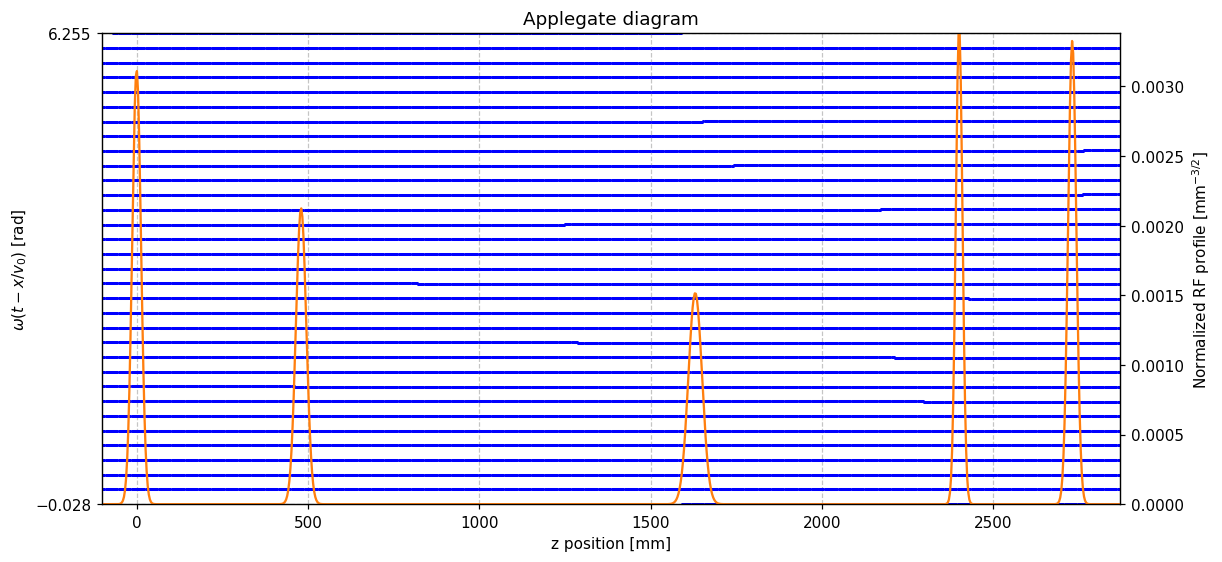

In [3]:
fig_applegate, (ax_phase, ax_field) = plot_applegate(
    dynamics, beam, grid, cavities, cavity_fields,
    ncenter=modulation["ncenter"], Ntp=Ntp, zmax=zmax,
)
fig_applegate.savefig(test_directory / "python_applegate.png", dpi=150)
plt.show()

## Current harmonics
Each curve is an already-normalized amplitude $|Iz_m|$. No further division
by `Iz0` is needed. Red dashed segments mark cavity centers, from 0 to 2 as in MATLAB.

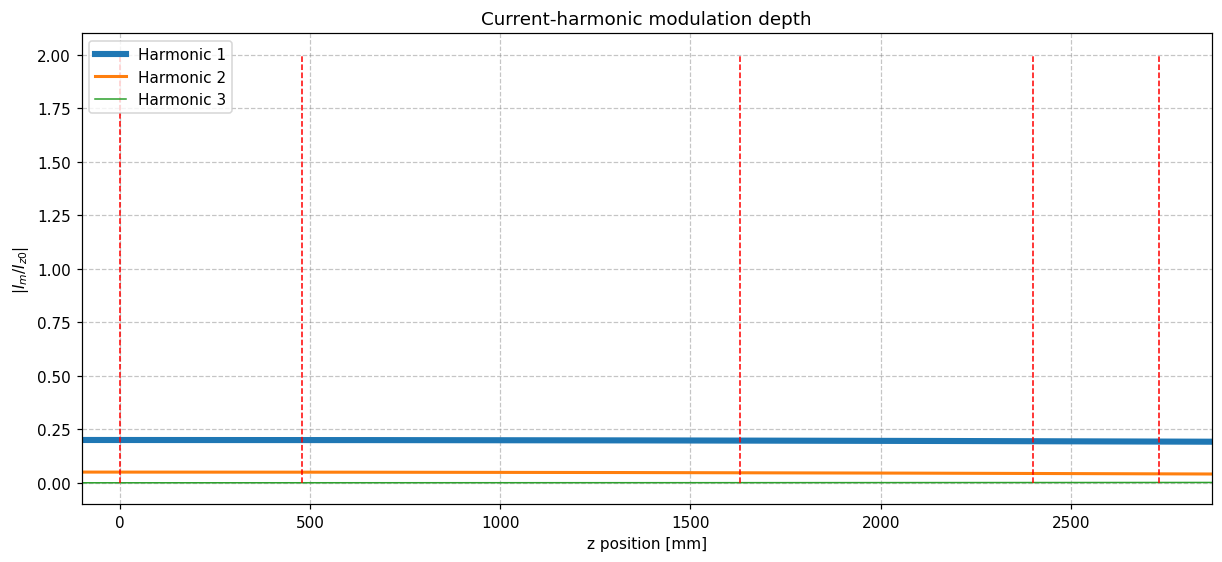

In [4]:
fig_harmonics, ax_harmonics = plot_current_harmonics(beam_state, grid, cavities, zmax=zmax)
fig_harmonics.savefig(test_directory / "python_current_harmonics.png", dpi=150)
plt.show()

## Export the actual plotted data
Read coordinates from the returned Matplotlib artists. Arrays retain history-row
alignment; omitted, unwritten entries are represented by NaN for comparison.
Python particle/grid indices remain zero-based in this export.

In [5]:
stride = max(int(np.floor(beam.Nt / Ntp + 0.5)), 1)
selected = np.intersect1d(dynamics.Y, np.arange(0, beam.Nt, stride))
x_phase = np.full((dynamics.Zn.shape[0], len(selected)), np.nan)
phase = np.full_like(x_phase, np.nan)
assert len(ax_phase.lines) == len(selected)
for column, (kp, line) in enumerate(zip(selected, ax_phase.lines)):
    valid = np.isfinite(dynamics.Zn[:, kp]) & np.isfinite(dynamics.Tn[:, kp])
    x_phase[valid, column] = line.get_xdata()
    phase[valid, column] = line.get_ydata()

Ns = beam_state.Iz.shape[1]
run_id = uuid4().hex
GIFpara = np.array(source_inputs["GIFpara"], dtype=float, copy=True)
GIFpara[0] = Ntp
GIFpara[4] = end_offset_mm
savemat(test_directory / "inputs.mat", dict(
    run_id=run_id, source_run_id=source_run_id, GIFpara=GIFpara,
), oned_as="row")
output = dict(
    run_id=run_id, source_run_id=source_run_id,
    **modulation, selected=selected, stride=stride,
    zi=grid.zi, x_phase=x_phase, phase=phase,
    ez_background=ax_field.lines[0].get_ydata(),
    harmonic_amplitudes=np.column_stack([line.get_ydata() for line in ax_harmonics.lines[:Ns]]),
    harmonic_widths=np.array([line.get_linewidth() for line in ax_harmonics.lines[:Ns]]),
    cavity_x=np.array([line.get_xdata() for line in ax_harmonics.lines[Ns:]]),
    cavity_y=np.array([line.get_ydata() for line in ax_harmonics.lines[Ns:]]),
    xlim=np.array(ax_phase.get_xlim()), phase_ylim=np.array(ax_phase.get_ylim()),
    field_ylim=np.array(ax_field.get_ylim()), harmonic_xlim=np.array(ax_harmonics.get_xlim()),
)
savemat(test_directory / "python_results.mat", output, oned_as="row")
print("Saved plot data and PNGs in", test_directory)
print("Next: run applegate_diagram_test.mlx, then compare_results.ipynb.")

Saved plot data and PNGs in C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\8.ApplegateDiagramTest
Next: run applegate_diagram_test.mlx, then compare_results.ipynb.
